In [2]:
print(f"CUDA Version: {torch.version.cuda}")

CUDA Version: 12.8


In [3]:
print(f"cuDNN Version: {torch.backends.cudnn.version()}")

cuDNN Version: 91002


In [4]:
if torch.cuda.is_available():
    print("GPU is available")
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
else:
    print("GPU is not available")

GPU is available
GPU Name: NVIDIA GeForce RTX 3080


In [ ]:
# 替代方案：手动查看关键包版本
import cell2location
import scanpy
import anndata
import torch

print(f"cell2location version: {cell2location.__version__}")
print(f"scanpy version: {scanpy.__version__}")
print(f"anndata version: {anndata.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")


/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [1]:
import torch

In [ ]:
def read_and_qc(sample_name, path):
    r""" This function reads the data for one 10X spatial experiment into the anndata object.
    It also calculates QC metrics. Modify this function if required by your workflow.

    :param sample_name: Name of the sample
    :param path: path to data
    """

    adata = sc.read_visium(path + str(sample_name),
                           count_file='filtered_feature_bc_matrix.h5', load_images=True,library_id=sample_name)
    adata.var_names_make_unique(join='-')
    
    adata.obs['sample'] = sample_name
    
    # rename genes to ENSEMBL
    adata.var['SYMBOL'] = adata.var_names
    adata.var_names = adata.var['gene_ids']
    adata.var_names.name = None

    # Calculate QC metrics
    sc.pp.calculate_qc_metrics(adata, inplace=True)
    adata.var['mt'] = [gene.startswith('MT-') for gene in adata.var['SYMBOL']]
    adata.obs['mt_frac'] = adata[:, adata.var['mt'].tolist()].X.sum(1).A.squeeze()/adata.obs['total_counts']

    # add sample name to obs names
    adata.obs["sample"] = [str(i) for i in adata.obs['sample']]
    adata.obs_names = adata.obs["sample"] \
                          + '_' + adata.obs_names
    adata.obs.index.name = 'spot_id'

    return adata

def select_slide(adata, s, s_col='sample'):
    r""" This function selects the data for one slide from the spatial anndata object.

    :param adata: Anndata object with multiple spatial experiments
    :param s: name of selected experiment
    :param s_col: column in adata.obs listing experiment name for each location
    """

    slide = adata[adata.obs[s_col].isin([s]), :]
    s_keys = list(slide.uns['spatial'].keys())
    s_spatial = np.array(s_keys)[[s in k for k in s_keys]][0]

    slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}

    return slide

In [3]:
import scanpy as sc

In [2]:
import sys
import scanpy as sc
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib as mpl

import scvi
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42 # enables correct plotting of text
import seaborn as sns

/home/data/t180330/miniconda3/envs/cell2loc/lib/python3.9/site-packages/scvi/__init__.py:31: DeprecationWarning: scvi is deprecated, please uninstall scvi via `pip uninstall scvi` and install the new scvi-tools package at github.com/YosefLab/scvi-tools
  warnings.warn(deprecation_msg, DeprecationWarning)


In [4]:
# setting scanpy
%matplotlib inline
sc.settings.verbosity = 3
sc.logging.print_version_and_date()

Running Scanpy 1.10.3, on 2025-11-29 02:10.


In [160]:
# First generate the reference data frame
inf_aver = pd.read_csv("/home/data/t180330/20250323/ref_sig_by_DEG1.csv", 
                       index_col = 0)

In [161]:
inf_aver

,CD4.CCR7,CD4.FOXP3,CD4.CXCL13,CD8.GZMK,CD8.CCL5,CD8.CXCL13,CD8.gdT.TRDC,NK.FCGR3A,NK.FGFBP2,Cycling.cells,...,Bn.TCL1A,Bmem,B.plasma.IgA,B.plasma.IgG,B.cycling,Endo.ACKR1,Endo.RGCC,Endo.LYVE1,Peri.RGS5,pDC.LILRA4
A2M,0.092084,0.039832,0.092733,0.154564,0.070148,0.034075,0.068240,0.138798,0.434220,0.030553,...,0.078584,0.367252,0.117340,0.025570,0.000000,10.223653,23.068481,1.725915,8.603084,0.116009
ABCA8,0.008491,0.003006,0.009202,0.016446,0.009066,0.004190,0.000000,0.008892,0.034638,0.003019,...,0.003761,0.015249,0.009615,0.001990,0.000000,0.034904,0.030477,0.083273,0.576020,0.000000
ABI3BP,0.014494,0.003983,0.014129,0.006882,0.016619,0.000000,0.027751,0.006647,0.010609,0.006048,...,0.036542,0.000000,0.016213,0.002284,0.000000,0.038652,0.037583,3.189043,0.167491,0.048714
ABL2,0.176152,0.091526,0.181827,0.188783,0.203811,0.055899,0.226069,0.190815,0.122256,0.015903,...,0.265337,0.337478,0.103926,0.080491,0.114542,2.242116,2.977509,0.744096,0.770614,0.165562
AC104024.1,0.002768,0.000000,0.002058,0.004217,0.000000,0.000000,0.000000,0.000000,0.000000,0.001292,...,0.145438,0.051880,0.250841,0.227770,0.136007,0.001399,0.000000,0.000000,0.000000,0.526329
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XCL1,0.317339,0.085815,0.730654,1.428266,7.154514,2.961101,11.769873,0.890853,0.167184,1.716022,...,0.021998,0.055340,0.028421,0.026197,0.186756,0.001613,0.004694,0.000000,0.010452,0.021395
XCL2,0.219739,0.021359,0.274400,2.457407,4.447376,4.005436,13.726181,3.735997,2.365028,1.616382,...,0.004954,0.022428,0.009377,0.014490,0.100034,0.000000,0.002299,0.000000,0.003502,0.016126
ZG16B,0.066256,0.162600,0.258312,0.043357,0.057510,0.014808,0.141988,0.090588,0.048267,0.053666,...,0.111607,0.103453,0.060593,0.067776,0.011236,0.029782,0.090516,0.181684,0.129761,0.016157
ZNF331,6.289901,4.174679,4.907561,5.875344,5.972715,2.244450,8.119903,2.003774,0.707762,1.872871,...,5.211104,4.364755,0.533309,0.427684,4.397960,0.182084,0.439231,0.375727,5.006711,8.327288


In [35]:
sp_data_folder = '/home/data/t180330/DHJ/'
results_folder = '/home/data/t180330/DHJ/deconvolution_models.all.subtypes/'

In [158]:
sample_names = ["CID44971","CID4465","1160920F","CID4290","CID4535","Visium","V1","V1_BlockA"]

In [162]:
slides = [read_and_qc(sample_name, path=sp_data_folder) for sample_name in sample_names]
adata_vis = slides[0].concatenate(slides[1:], batch_key="sample", uns_merge="unique", batch_categories=sample_names, index_unique=None)

/tmp/ipykernel_3410972/2481217173.py:9: FutureWarning: Use `squidpy.read.visium` instead.
  adata = sc.read_visium(path + str(sample_name),
/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/tmp/ipykernel_3410972/2481217173.py:9: FutureWarning: Use `squidpy.read.visium` instead.
  adata = sc.read_visium(path + str(sample_name),
/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var

In [148]:
adata_vis

AnnData object with n_obs × n_vars = 9804 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac'
    var: 'gene_ids', 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-CRC01', 'mean_counts-CRC01', 'log1p_mean_counts-CRC01', 'pct_dropout_by_counts-CRC01', 'total_counts-CRC01', 'log1p_total_counts-CRC01', 'n_cells_by_counts-CRC06', 'mean_counts-CRC06', 'log1p_mean_counts-CRC06', 'pct_dropout_by_counts-CRC06', 'total_counts-CRC06', 'log1p_total_counts-CRC06', 'n_cells_by_counts-CRC06T', 'mean_counts-CRC06T', 'log1p_mean_counts-CRC06T', 'pct_dropout_by_counts-CRC06T', 'total_counts-CRC06T', 'log1p_total_counts-CRC06T', 'n_cells_by_counts-CRC07', 'mean_counts-CRC07', 'log1p_mean_counts-CRC07', 'pct_dropout_by_counts-CRC07', 'total_counts-CRC07', 'log1p_

In [7]:
import os
import scanpy as sc
import anndata as ad
import pandas as pd

# --- 1. 设置参数 ---
data_folder = "/home/data/t180330/Visium_human_breast_cancer/"
output_filename = "merged_human_breast_cancer_spatial_with_uns.h5ad" # 输出文件名改一下，避免混淆

# --- 2. 获取所有 h5ad 文件路径 ---
h5ad_files = [os.path.join(data_folder, f) for f in os.listdir(data_folder) if f.endswith('.h5ad')]
h5ad_files.sort() # 排序，确保顺序一致
print(f"Found {len(h5ad_files)} .h5ad files to merge.")

# --- 3. 逐个加载并准备数据 ---
adatas = []
spatial_info_list = [] # 用于存储每个样本的空间信息

for i, file_path in enumerate(h5ad_files):
    print(f"Loading {os.path.basename(file_path)}...")
    adata = sc.read_h5ad(file_path)
    
    # 从文件名中提取样本ID，作为批次标签
    sample_id = os.path.basename(file_path).replace('.h5ad', '')
    adata.obs['sample_id'] = sample_id
    
    # 检查并保存空间信息
    if 'spatial' in adata.uns:
        # 将空间信息与样本ID关联起来，存入列表
        spatial_info_list.append({
            'sample_id': sample_id,
            'spatial_dict': adata.uns['spatial']
        })
        # 从原始adata中移除spatial信息，避免concat时冲突
        del adata.uns['spatial']
    else:
        print(f"  Warning: No 'spatial' key found in uns for {sample_id}. Skipping spatial info for this sample.")
        
    adatas.append(adata)

# --- 4. 执行合并 ---
# 明确告诉 concat 如何处理 obs 和 var，并忽略 uns
print("\nConcatenating AnnData objects...")
adata_merged = ad.concat(
    adatas, 
    join='outer',  # 保留所有基因
    label='sample_id', # 将样本ID作为批次标签的来源
    keys=[a.obs['sample_id'][0] for a in adatas], # 提供每个样本的ID
    index_unique='-', # 如果obs名重复，添加后缀
    merge='unique' # 对于uns，只保留唯一的键
)

# --- 5. 重建 uns['spatial'] 字典 ---
print("\nReconstructing 'spatial' information in merged object...")
adata_merged.uns['spatial'] = {}
for info in spatial_info_list:
    sample_id = info['sample_id']
    spatial_dict = info['spatial_dict']
    # 将该样本的空间信息添加到合并对象的uns中
    adata_merged.uns['spatial'][sample_id] = spatial_dict

print(f"Successfully reconstructed spatial info for {len(adata_merged.uns['spatial'])} samples.")

# --- 6. 保存合并后的文件 ---
print(f"\nSaving merged data to {output_filename}...")
adata_merged.write(output_filename)
print("Done!")

# --- 7. 验证 ---
# 重新加载文件，检查spatial信息是否存在
print("\n--- Verification ---")
ad2 = sc.read_h5ad(output_filename)
print(f"Shape of merged adata: {ad2.shape}")
print(f"Unique sample_ids in obs: {ad2.obs['sample_id'].unique().tolist()}")
print(f"Keys in 'spatial' dictionary in uns: {list(ad2.uns['spatial'].keys())}")

Found 11 .h5ad files to merge.
Loading human_bc_spatial_1142243F.h5ad...
Loading human_bc_spatial_1160920F.h5ad...
Loading human_bc_spatial_CID4290.h5ad...
Loading human_bc_spatial_CID4465.h5ad...
Loading human_bc_spatial_CID44971.h5ad...
Loading human_bc_spatial_CID4535.h5ad...
Loading human_bc_spatial_Parent_Visium_Human_BreastCancer.h5ad...
Loading human_bc_spatial_V1_Breast_Cancer_Block_A_Section_1.h5ad...
Loading human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2.h5ad...
Loading human_bc_spatial_V1_Human_Invasive_Ductal_Carcinoma.h5ad...
Loading human_bc_spatial_Visium_FFPE_Human_Breast_Cancer.h5ad...

Concatenating AnnData objects...


/tmp/ipykernel_3410972/695656449.py:48: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  keys=[a.obs['sample_id'][0] for a in adatas], # 提供每个样本的ID



Reconstructing 'spatial' information in merged object...
Successfully reconstructed spatial info for 11 samples.

Saving merged data to merged_human_breast_cancer_spatial_with_uns.h5ad...
Done!

--- Verification ---
Shape of merged adata: (34966, 28786)
Unique sample_ids in obs: ['human_bc_spatial_1142243F', 'human_bc_spatial_1160920F', 'human_bc_spatial_CID4290', 'human_bc_spatial_CID4465', 'human_bc_spatial_CID44971', 'human_bc_spatial_CID4535', 'human_bc_spatial_Parent_Visium_Human_BreastCancer', 'human_bc_spatial_V1_Breast_Cancer_Block_A_Section_1', 'human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2', 'human_bc_spatial_V1_Human_Invasive_Ductal_Carcinoma', 'human_bc_spatial_Visium_FFPE_Human_Breast_Cancer']
Keys in 'spatial' dictionary in uns: ['human_bc_spatial_1142243F', 'human_bc_spatial_1160920F', 'human_bc_spatial_CID4290', 'human_bc_spatial_CID4465', 'human_bc_spatial_CID44971', 'human_bc_spatial_CID4535', 'human_bc_spatial_Parent_Visium_Human_BreastCancer', 'human_bc_spati

In [9]:
# --- 3. Loop Through Samples and Calculate Dimensions ---
# We'll store the results in a dictionary for easy access.
sample_dimensions = {}
sample_ids = adata_merged.obs['sample_id'].unique()
print("--- Calculating Dimensions for Each Sample ---")
for sample_id in sample_ids:
    # Create a boolean mask to select rows (cells/spots) belonging to the current sample
    mask = adata_merged.obs['sample_id'] == sample_id
    
    # Subset the AnnData object using the mask
    adata_subset = adata_merged[mask]
    
    # Get the shape (number of cells, number of genes)
    n_cells, n_genes = adata_subset.shape
    
    # Store the dimensions in our dictionary
    sample_dimensions[sample_id] = {'cells': n_cells, 'genes': n_genes}
    
    # Print the result for the current sample
    print(f"Sample: {sample_id:<55} | Cells: {n_cells:<6} | Genes: {n_genes}")

print("\n--- Calculation Complete ---")


--- Calculating Dimensions for Each Sample ---
Sample: human_bc_spatial_1142243F                               | Cells: 4784   | Genes: 28786
Sample: human_bc_spatial_1160920F                               | Cells: 4895   | Genes: 28786
Sample: human_bc_spatial_CID4290                                | Cells: 2432   | Genes: 28786
Sample: human_bc_spatial_CID4465                                | Cells: 1211   | Genes: 28786
Sample: human_bc_spatial_CID44971                               | Cells: 1162   | Genes: 28786
Sample: human_bc_spatial_CID4535                                | Cells: 1127   | Genes: 28786
Sample: human_bc_spatial_Parent_Visium_Human_BreastCancer       | Cells: 4325   | Genes: 28786
Sample: human_bc_spatial_V1_Breast_Cancer_Block_A_Section_1     | Cells: 3798   | Genes: 28786
Sample: human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2     | Cells: 3987   | Genes: 28786
Sample: human_bc_spatial_V1_Human_Invasive_Ductal_Carcinoma     | Cells: 4727   | Genes: 28786
Sam

In [160]:
adata_merged

AnnData object with n_obs × n_vars = 34966 × 28786
    obs: 'nCount_RNA', 'nFeature_RNA', 'patientid', 'subtype', 'Classification', 'sample_id', 'in_tissue', 'array_row', 'array_col', 'n_genes'
    uns: 'spatial'
    obsm: 'spatial'

In [161]:
adata_vis = adata_merged

In [163]:
# Assign the 'SYMBOL' column from your var dataframe to be the new index names
adata_vis.var_names = adata_vis.var['SYMBOL']


# Now, check intersectthe result
print(adata_vis.var_names[:10]) # Print the first 10 gene names

array(['A2M', 'ABCA8', 'ABI3BP', 'ABL2', 'AC104024.1', 'ACKR1', 'ACKR4',
       'ACP5', 'ACTA2', 'ACTG2', 'ADAM12', 'ADAMDEC1', 'ADAMTS1',
       'ADAMTS16', 'ADAMTS4', 'ADAMTS5', 'ADAMTS9', 'ADAP2', 'ADGRE2',
       'ADGRF5', 'ADGRL4', 'ADM', 'ADM5', 'AEBP1', 'AFF3', 'AGR2', 'AGR3',
       'AIF1', 'AK5', 'AKAP12', 'AKR1C3', 'ALDH1A1', 'ALDH1A3', 'ALOX5AP',
       'ALPL', 'ANGPT2', 'ANGPTL2', 'ANGPTL4', 'ANK2', 'ANKRD29',
       'ANKRD36C', 'ANKRD37', 'ANPEP', 'ANXA3', 'APLNR', 'APOBEC3A',
       'APOC1', 'APOD', 'APOE', 'APOLD1', 'AQP1', 'AQP3', 'AQP5', 'AR',
       'AREG', 'ARHGAP29', 'ASPN', 'ATF3', 'ATF5', 'ATP1B1', 'AVPR1A',
       'AZGP1', 'BAMBI', 'BASP1', 'BATF', 'BBOX1', 'BCAM', 'BCL2A1',
       'BGN', 'BIRC3', 'C12orf75', 'C15orf48', 'C16orf89', 'C19orf33',
       'C1QA', 'C1QB', 'C1QC', 'C1R', 'C1S', 'C1orf162', 'C1orf54',
       'C2CD4B', 'C3', 'C3AR1', 'C5AR1', 'C5AR2', 'C7', 'CA2', 'CADM3',
       'CALB2', 'CALCRL', 'CALD1', 'CALML5', 'CAPG', 'CAPN8', 'CARMN',
       'CAV

In [164]:
interse


ct = np.intersect1d(adata_vis.var_names, inf_aver.index)

In [156]:
adata_vis = adata_vis[:, intersect].copy()

In [142]:
inf_aver = inf_aver.loc[intersect, :].copy()

In [143]:
inf_aver

,CD4.CCR7,CD4.FOXP3,CD4.CXCL13,CD8.GZMK,CD8.CCL5,CD8.CXCL13,CD8.gdT.TRDC,NK.FCGR3A,NK.FGFBP2,Cycling.cells,...,Bn.TCL1A,Bmem,B.plasma.IgA,B.plasma.IgG,B.cycling,Endo.ACKR1,Endo.RGCC,Endo.LYVE1,Peri.RGS5,pDC.LILRA4
A2M,0.092084,0.039832,0.092733,0.154564,0.070148,0.034075,0.068240,0.138798,0.434220,0.030553,...,0.078584,0.367252,0.117340,0.025570,0.000000,10.223653,23.068481,1.725915,8.603084,0.116009
ABCA8,0.008491,0.003006,0.009202,0.016446,0.009066,0.004190,0.000000,0.008892,0.034638,0.003019,...,0.003761,0.015249,0.009615,0.001990,0.000000,0.034904,0.030477,0.083273,0.576020,0.000000
ABI3BP,0.014494,0.003983,0.014129,0.006882,0.016619,0.000000,0.027751,0.006647,0.010609,0.006048,...,0.036542,0.000000,0.016213,0.002284,0.000000,0.038652,0.037583,3.189043,0.167491,0.048714
ABL2,0.176152,0.091526,0.181827,0.188783,0.203811,0.055899,0.226069,0.190815,0.122256,0.015903,...,0.265337,0.337478,0.103926,0.080491,0.114542,2.242116,2.977509,0.744096,0.770614,0.165562
AC104024.1,0.002768,0.000000,0.002058,0.004217,0.000000,0.000000,0.000000,0.000000,0.000000,0.001292,...,0.145438,0.051880,0.250841,0.227770,0.136007,0.001399,0.000000,0.000000,0.000000,0.526329
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XCL1,0.317339,0.085815,0.730654,1.428266,7.154514,2.961101,11.769873,0.890853,0.167184,1.716022,...,0.021998,0.055340,0.028421,0.026197,0.186756,0.001613,0.004694,0.000000,0.010452,0.021395
XCL2,0.219739,0.021359,0.274400,2.457407,4.447376,4.005436,13.726181,3.735997,2.365028,1.616382,...,0.004954,0.022428,0.009377,0.014490,0.100034,0.000000,0.002299,0.000000,0.003502,0.016126
ZG16B,0.066256,0.162600,0.258312,0.043357,0.057510,0.014808,0.141988,0.090588,0.048267,0.053666,...,0.111607,0.103453,0.060593,0.067776,0.011236,0.029782,0.090516,0.181684,0.129761,0.016157
ZNF331,6.289901,4.174679,4.907561,5.875344,5.972715,2.244450,8.119903,2.003774,0.707762,1.872871,...,5.211104,4.364755,0.533309,0.427684,4.397960,0.182084,0.439231,0.375727,5.006711,8.327288


In [ ]:
    # Training cell2location
    cell2location.models.Cell2location.setup_anndata(adata=adata_vis, batch_key="sample_id")
    mod = cell2location.models.Cell2location(adata_vis,
                                             cell_state_df=inf_aver,
                                             detection_alpha=200, # Controls the normalisation of the within-experiment variation of the RNA detection (default value for now)
                                             N_cells_per_location=8
                                             )

In [ ]:
mod.train(max_epochs=20000, 
          # train using full data (batch_size=None)
          batch_size=None, 
          # use all data points in training because 
          # we need to estimate cell abundance at all locations
          train_size=1)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
You are using a CUDA device ('NVIDIA GeForce RTX 3080') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/data/t180330/miniconda3/envs/cell2loc_env/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_worke

Epoch 20000/20000: 100%|██████████| 20000/20000 [24:41<00:00, 14.29it/s, v_num=1, elbo_train=4.83e+6]

`Trainer.fit` stopped: `max_epochs=20000` reached.


Epoch 20000/20000: 100%|██████████| 20000/20000 [24:41<00:00, 13.50it/s, v_num=1, elbo_train=4.83e+6]


In [ ]:
adata_vis = mod.export_posterior(adata_vis, sample_kwargs={'num_samples': 1000, 'batch_size': 2500})
adata_vis.write("/home/data/t180330/Visium_humcan_breast_caner/deconvolution_models/sp.h5ad")

Sampling global variables, sample: 100%|██████████| 999/999 [00:13<00:00, 73.95it/s]


In [92]:
ad2 = sc.read_h5ad('/home/data/t180330/Visium_human_breast_cancer/deconvolution_models/sp.h5ad')

In [94]:
adata_vis = ad2

In [36]:
adata_vis.obs[adata_vis.uns['mod']['factor_names']] = adata_vis.obsm['q05_cell_abundance_w_sf']

In [175]:
adata_vis

AnnData object with n_obs × n_vars = 9804 × 917
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', '_indices', '_scvi_batch', '_scvi_labels', 'CD4.CCR7', 'CD4.FOXP3', 'CD4.CXCL13', 'CD8.GZMK', 'CD8.CCL5', 'CD8.CXCL13', 'CD8.gdT.TRDC', 'NK.FCGR3A', 'NK.FGFBP2', 'Cycling.cells', 'Stress.cells', 'Basal.myoepithelial', 'Luminal', 'Fibro.PI16', 'Fibro.CXCL1', 'Fibro.POSTN', 'Mono.FCN1', 'Macro.FOLR2', 'Macro.SPP1', 'Macro.C1QC', 'Macro.CXCL10', 'cDC1.CLEC9A', 'cDC2.CD1C', 'cDC3.LAMP3', 'Bn.TCL1A', 'Bmem', 'B.plasma.IgA', 'B.plasma.IgG', 'B.cycling', 'Endo.ACKR1', 'Endo.RGCC', 'Endo.LYVE1', 'Peri.RGS5', 'pDC.LILRA4'
    var: 'gene_ids', 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-CRC01', 'mean_counts-CRC01', 'log1p_mean_counts-CRC01', 'pct_dropout_by_

In [14]:
adata_vis

AnnData object with n_obs × n_vars = 34966 × 917
    obs: 'nCount_RNA', 'nFeature_RNA', 'patientid', 'subtype', 'Classification', 'sample_id', 'in_tissue', 'array_row', 'array_col', 'n_genes', '_indices', '_scvi_batch', '_scvi_labels', 'CD4.CCR7', 'CD4.FOXP3', 'CD4.CXCL13', 'CD8.GZMK', 'CD8.CCL5', 'CD8.CXCL13', 'CD8.gdT.TRDC', 'NK.FCGR3A', 'NK.FGFBP2', 'Cycling.cells', 'Stress.cells', 'Basal.myoepithelial', 'Luminal', 'Fibro.PI16', 'Fibro.CXCL1', 'Fibro.POSTN', 'Mono.FCN1', 'Macro.FOLR2', 'Macro.SPP1', 'Macro.C1QC', 'Macro.CXCL10', 'cDC1.CLEC9A', 'cDC2.CD1C', 'cDC3.LAMP3', 'Bn.TCL1A', 'Bmem', 'B.plasma.IgA', 'B.plasma.IgG', 'B.cycling', 'Endo.ACKR1', 'Endo.RGCC', 'Endo.LYVE1', 'Peri.RGS5', 'pDC.LILRA4'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'mod', 'spatial'
    obsm: 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf'

In [16]:
cell_type_columns = [
    'CD4.CCR7', 'CD4.FOXP3', 'CD4.CXCL13',
    'CD8.GZMK', 'CD8.CCL5', 'CD8.CXCL13', 'CD8.gdT.TRDC',
    'NK.FCGR3A', 'NK.FGFBP2',
    'Cycling.cells', 'Stress.cells',
    'Basal.myoepithelial', 'Luminal',
    'Fibro.PI16', 'Fibro.CXCL1', 'Fibro.POSTN',
    'Mono.FCN1', 'Macro.FOLR2', 'Macro.SPP1', 'Macro.C1QC', 'Macro.CXCL10',
    'cDC1.CLEC9A', 'cDC2.CD1C', 'cDC3.LAMP3',
    'Bn.TCL1A', 'Bmem', 'B.plasma.IgA', 'B.plasma.IgG', 'B.cycling',
    'Endo.ACKR1', 'Endo.RGCC', 'Endo.LYVE1',
    'Peri.RGS5', 'pDC.LILRA4'
]
# 提取这些列，并确保包含细胞ID（index）
df_cell_types = adata_vis.obs[cell_type_columns].copy()
df_cell_types.index.name = "cell_id"  # 给索引列命名，便于后续识别

# 保存为 CSV
df_cell_types.to_csv("/home/data/t180330/Visium_human_breast_cancer/q05_cell_abundance_w_sf.csv")

In [18]:
c2l = pd.read_csv("/home/data/t180330/Visium_human_breast_cancer/q05_cell_abundance_w_sf.csv",
                  sep = ",",index_col=0)
c2l.head()

,CD4.CCR7,CD4.FOXP3,CD4.CXCL13,CD8.GZMK,CD8.CCL5,CD8.CXCL13,CD8.gdT.TRDC,NK.FCGR3A,NK.FGFBP2,Cycling.cells,...,Bn.TCL1A,Bmem,B.plasma.IgA,B.plasma.IgG,B.cycling,Endo.ACKR1,Endo.RGCC,Endo.LYVE1,Peri.RGS5,pDC.LILRA4
cell_id,,,,,,,,,,,,,,,,,,,,,
TACCGATCCAACACTT-1-human_bc_spatial_1142243F,0.019943,0.048143,0.026475,0.018543,0.019584,0.028703,0.021129,0.019913,0.021440,0.025767,...,0.022497,0.020193,0.037475,0.018498,0.020019,0.011983,0.009109,0.014215,0.019473,0.009101
GATAAGGGACGATTAG-1-human_bc_spatial_1142243F,0.029603,0.033376,0.031033,0.028395,0.026130,0.019273,0.021885,0.034227,0.031305,0.024433,...,0.016061,0.019979,0.095420,0.032412,0.016224,0.008209,0.034733,0.011401,0.010949,0.006740
TGTTGGCTGGCGGAAG-1-human_bc_spatial_1142243F,0.019749,0.023048,0.021982,0.016612,0.017916,0.013195,0.015450,0.013968,0.017878,0.025160,...,0.016862,0.015967,0.074918,0.023124,0.016222,0.007795,0.025165,0.007139,0.105439,0.008383
GCGAGGGACTGCTAGA-1-human_bc_spatial_1142243F,0.061594,0.058314,0.058346,0.054755,0.046993,0.047747,0.033597,0.027605,0.046175,0.065560,...,0.057609,0.056430,0.107111,0.061022,0.049856,0.021872,0.041612,0.009397,0.026771,0.024351
GCGCGTTTAAATCGTA-1-human_bc_spatial_1142243F,0.058182,0.042610,0.062417,0.051961,0.042236,0.054014,0.032216,0.027268,0.035833,0.066855,...,0.057001,0.053200,0.216506,0.042934,0.065179,0.014382,0.014198,0.012688,0.126112,0.019982


In [ ]:
read("/home/data/t180330/CRC-10Z/deconvolution_models/sp.h5ad")

In [134]:
ad2.obsm

AxisArrays with keys: spatial, means_cell_abundance_w_sf, stds_cell_abundance_w_sf, q05_cell_abundance_w_sf, q95_cell_abundance_w_sf

In [25]:
def select_slide(adata, s, s_col='sample_id'):
    r""" This function selects the data for one slide from the spatial anndata object.

    :param adata: Anndata object with multiple spatial experiments
    :param s: name of selected experiment
    :param s_col: column in adata.obs listing experiment name for each location
    """

    slide = adata[adata.obs[s_col].isin([s]), :]
    s_keys = list(slide.uns['spatial'].keys())
    s_spatial = np.array(s_keys)[[s in k for k in s_keys]][0]

    slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}

    return slide


In [30]:
adata_vis = sc.read_h5ad("/home/data/t180330/CRC-10Z/deconvolution_models/sp.h5ad")

In [31]:
adata_vis

AnnData object with n_obs × n_vars = 9804 × 917
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', '_indices', '_scvi_batch', '_scvi_labels'
    var: 'gene_ids', 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-CRC01', 'mean_counts-CRC01', 'log1p_mean_counts-CRC01', 'pct_dropout_by_counts-CRC01', 'total_counts-CRC01', 'log1p_total_counts-CRC01', 'n_cells_by_counts-CRC06', 'mean_counts-CRC06', 'log1p_mean_counts-CRC06', 'pct_dropout_by_counts-CRC06', 'total_counts-CRC06', 'log1p_total_counts-CRC06', 'n_cells_by_counts-CRC06T', 'mean_counts-CRC06T', 'log1p_mean_counts-CRC06T', 'pct_dropout_by_counts-CRC06T', 'total_counts-CRC06T', 'log1p_total_counts-CRC06T', 'n_cells_by_counts-CRC07', 'mean_counts-CRC07', 'log1p_mean_counts-CRC07', 'pct_dropout_by_cou

In [33]:
# 使用我们新的健壮函数来提取样本
# 请确保 "V1" 是 ad2.obs['sample'] 列中的一个有效值
slide_v1 = select_slide(adata_vis, "CRC06T")

/tmp/ipykernel_2760132/2563771768.py:13: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}


In [125]:
# 使用我们新的健壮函数来提取样本
# 请确保 "V1" 是 ad2.obs['sample'] 列中的一个有效值
slide_v1 = select_slide(adata_vis, "human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2")

/tmp/ipykernel_3410972/4044982404.py:13: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}


In [29]:
# See all unique sample names in your observations
print("Unique sample names in adata.obs:")
print(adata_vis.obs['sample_id'].unique())

Unique sample names in adata.obs:
['human_bc_spatial_1142243F', 'human_bc_spatial_1160920F', 'human_bc_spatial_CID4290', 'human_bc_spatial_CID4465', 'human_bc_spatial_CID44971', ..., 'human_bc_spatial_Parent_Visium_Human_BreastCa..., 'human_bc_spatial_V1_Breast_Cancer_Block_A_Sec..., 'human_bc_spatial_V1_Breast_Cancer_Block_A_Sec..., 'human_bc_spatial_V1_Human_Invasive_Ductal_Car..., 'human_bc_spatial_Visium_FFPE_Human_Breast_Can...]
Length: 11
Categories (11, object): ['human_bc_spatial_1142243F', 'human_bc_spatial_1160920F', 'human_bc_spatial_CID4290', 'human_bc_spatial_CID4465', ..., 'human_bc_spatial_V1_Breast_Cancer_Block_A_Sec..., 'human_bc_spatial_V1_Breast_Cancer_Block_A_Sec..., 'human_bc_spatial_V1_Human_Invasive_Ductal_Car..., 'human_bc_spatial_Visium_FFPE_Human_Breast_Can...]


In [24]:
adata_vis

AnnData object with n_obs × n_vars = 34966 × 917
    obs: 'nCount_RNA', 'nFeature_RNA', 'patientid', 'subtype', 'Classification', 'sample_id', 'in_tissue', 'array_row', 'array_col', 'n_genes', '_indices', '_scvi_batch', '_scvi_labels', 'CD4.CCR7', 'CD4.FOXP3', 'CD4.CXCL13', 'CD8.GZMK', 'CD8.CCL5', 'CD8.CXCL13', 'CD8.gdT.TRDC', 'NK.FCGR3A', 'NK.FGFBP2', 'Cycling.cells', 'Stress.cells', 'Basal.myoepithelial', 'Luminal', 'Fibro.PI16', 'Fibro.CXCL1', 'Fibro.POSTN', 'Mono.FCN1', 'Macro.FOLR2', 'Macro.SPP1', 'Macro.C1QC', 'Macro.CXCL10', 'cDC1.CLEC9A', 'cDC2.CD1C', 'cDC3.LAMP3', 'Bn.TCL1A', 'Bmem', 'B.plasma.IgA', 'B.plasma.IgG', 'B.cycling', 'Endo.ACKR1', 'Endo.RGCC', 'Endo.LYVE1', 'Peri.RGS5', 'pDC.LILRA4'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'mod', 'spatial'
    obsm: 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf'

In [126]:
import matplotlib.pyplot as plt

# 1. 加载你的图像文件S
image_path = "/home/data/t180330/DHJ/V1_BlockA_section2/spatial/tissue_hires_image.png"
img = plt.imread(image_path)

# 2. 找到你的 library_id
library_id = list(slide_v1.uns['spatial'].keys())[0]

# 3. 手动创建 'images' 字典并添加图像
if 'images' not in slide_v1.uns['spatial'][library_id]:
    slide_v1.uns['spatial'][library_id]['images'] = {}
slide_v1.uns['spatial'][library_id]['images']['hires'] = img


In [127]:
# 0. 首先导入 json 模块
import json

# 1. 定义你的样本名和 scalefactors 文件路径
# 请确保这个路径是正确的
sample_name = "V1_BlockA_section2"  # 这是我根据你之前的路径猜测的，如果不是，请修改
scalefactors_path = "/home/data/t180330/DHJ/V1_BlockA_section2/spatial/scalefactors_json.json"

# 2. 从文件中加载 scalefactors 数据
with open(scalefactors_path, 'r') as f:
    scalefactors_data = json.load(f)

# 3. 获取当前 slide 对象中的 library_id
# 因为我们用 selectslide 筛选过了，所以应该只有一个 key
# 我们把它取出来
library_id = list(slide_v1.uns['spatial'].keys())[0]

# 4. 将加载的 scalefactors 数据添加到 slide_v1 对象的正确位置
slide_v1.uns['spatial'][library_id]['scalefactors'] = scalefactors_data

print("成功将 scalefactors 添加到 slide_v1 对象中！")


成功将 scalefactors 添加到 slide_v1 对象中！


In [90]:
slide_v1

AnnData object with n_obs × n_vars = 2432 × 917
    obs: 'nCount_RNA', 'nFeature_RNA', 'patientid', 'subtype', 'Classification', 'sample_id', 'in_tissue', 'array_row', 'array_col', 'n_genes', '_indices', '_scvi_batch', '_scvi_labels', 'leiden', 'region_cluster'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'mod', 'spatial', 'neighbors', 'leiden', 'umap', 'region_cluster_colors', 'sample_id_colors'
    obsm: 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf', 'X_umap'
    obsp: 'distances', 'connectivities'

/tmp/ipykernel_3410972/868759918.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(slide_v1, cmap='magma',


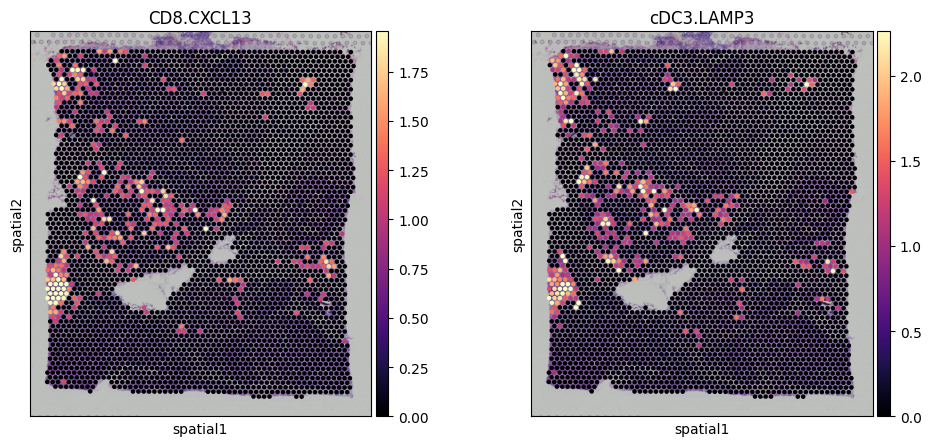

In [128]:
    sc.pl.spatial(slide_v1, cmap='magma',
                  # show first 8 cell types
                  color=['CD8.CXCL13','cDC3.LAMP3'],
                  ncols=2, size=1.3,
                  img_key='hires',
                  # limit color scale at 99.2% quantile of cell abundance
                  vmin=0, vmax='p99.2'
                 )

In [45]:
# 使用我们新的健壮函数来提取样本
# 请确保 "V1" 是 ad2.obs['sample'] 列中的一个有效值
slide_v1 = select_slide(adata_vis, "CRC07")

/tmp/ipykernel_2760132/2563771768.py:13: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}


In [46]:
plt.switch_backend('pdf')

# plot in spatial coordinates
with mpl.rc_context({'axes.facecolor':  'black',
                     'figure.figsize': [9, 10]}):

    sc.pl.spatial(slide_v1, cmap='magma',
                  # show first 8 cell types
                  color=['CD8.CXCL13','cDC3.LAMP3'],
                  ncols=2, size=1.3,
                  img_key='hires',
                  # limit color scale at 99.2% quantile of cell abundance
                  vmin=0, vmax='p99.2'
                 )
plt.savefig('/home/data/t180330/CRC-10Z/CRC07.pdf')
#如果你想要图形在Notebook中显示，可以再次将后端切换回'inline'
plt.switch_backend('inline')

/tmp/ipykernel_2760132/3678259062.py:17: MatplotlibDeprecationWarning: Auto-close()ing of figures upon backend switching is deprecated since 3.8 and will be removed in 3.10.  To suppress this warning, explicitly call plt.close('all') first.
  plt.switch_backend('inline')


In [69]:
gene_list = ["CCL19","CCL21","CXCL13","CCR7","SELL","LAMP3","CXCR4","CD86","BCL6"]

In [70]:
 # 使用我们新的健壮函数来提取样本
# 请确保 "V1" 是 ad2.obs['sample'] 列中的一个有效值
slides = select_slide(adata_vis, "CRC01")

/tmp/ipykernel_2760132/2563771768.py:13: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  slide.uns['spatial'] = {s_spatial: slide.uns['spatial'][s_spatial]}


In [71]:
sc.tl.score_genes(slides, gene_list = gene_list, score_name = 'TLS_score')

computing score 'TLS_score'
    finished: added
    'TLS_score', score of gene set (adata.obs).
    183 total control genes are used. (0:00:00)


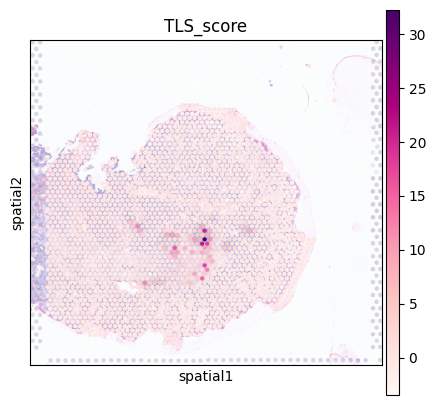

In [ ]:
plt.rcParams["figure.figsize"] = (5, 5)
sc.pl.spatial(slides,
             color=['TLS_score'],
             cmap='RdPu',
             size =1.3,
             alpha_img=0.5,
             ncols=2,
             save='CRC01.TL.pdf')

In [54]:
!pwd

/home/data/t180330/data_transfer
